# 01 - Exploration du jeu de données SmartFire-30 v1

Objectif (brief 05, étape C) : comprendre les données avant de modéliser et justifier la **fusion multi-capteurs** (innovation A). Un détecteur qui ne regarde que `gaz` peut-il distinguer une perturbation (classe 1) d'un incendie (classe 2) ?

Règles de ce notebook :
- l'exploration se fait sur le split **train** seulement : ni la validation ni le test ne sont regardés ;
- les chiffres sont mesurés sur le jeu synthétique [M] et ne disent rien sur de vrais capteurs ;
- `episode_id`, `kind` et `split` sont des métadonnées, jamais des features.


In [1]:
import sys
from pathlib import Path

# find the repository root whatever the folder the notebook is opened from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "dataset_v1.csv").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

from ia.generator import FEATURES

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

KINDS = ["normal", "cuisson", "vapeur", "incendie", "couvant"]
CLASS_NAMES = {0: "0 normal", 1: "1 perturbation", 2: "2 incendie"}
COLORS = {0: "tab:green", 1: "tab:orange", 2: "tab:red"}
SEUIL_CLASSIQUE = 2000  # contract v1.0, section 3

df = pd.read_csv(ROOT / "data" / "dataset_v1.csv")
assert list(df.columns) == [*FEATURES, "y", "episode_id", "kind", "split"]
assert not {"y", "episode_id", "kind", "split"} & set(FEATURES)  # leak protection
train = df[df["split"] == "train"].copy()
print(f"dataset v1 : {len(df)} rows, {df['episode_id'].nunique()} episodes [M]")
print(f"exploration on train only : {len(train)} rows, {train['episode_id'].nunique()} episodes [M]")


dataset v1 : 82829 rows, 510 episodes [M]
exploration on train only : 58550 rows, 357 episodes [M]


## 1. Répartition des classes

Combien de lignes par classe, dans chaque split, et combien d'épisodes par type de scénario ?


rows per class and split [M]
       0 normal  1 perturbation  2 incendie
split                                      
train     25343           18605       14602
val        4742            3537        3371
test       6266            2974        3389

share of each class inside a split (%) [M]
       0 normal  1 perturbation  2 incendie
split                                      
train      43.3            31.8        24.9
val        40.7            30.4        28.9
test       49.6            23.5        26.8


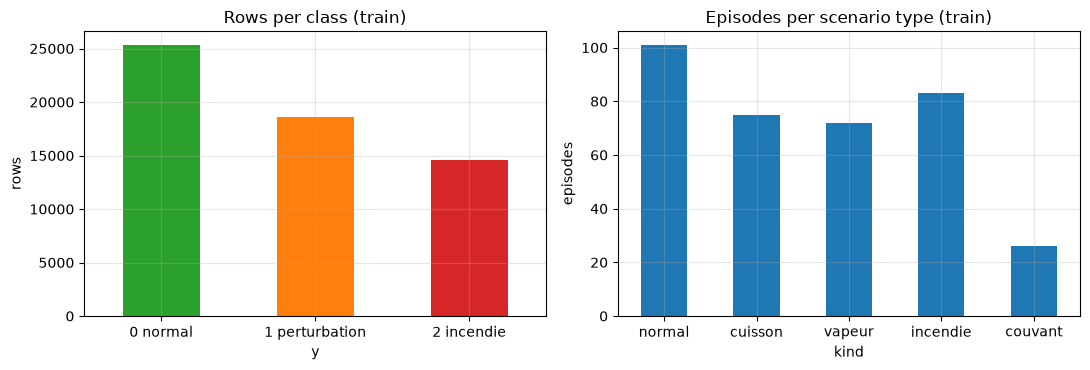

In [2]:
counts = pd.crosstab(df["split"], df["y"]).reindex(["train", "val", "test"])
counts.columns = [CLASS_NAMES[c] for c in counts.columns]
print("rows per class and split [M]")
print(counts.to_string())
print()
print("share of each class inside a split (%) [M]")
print((counts.div(counts.sum(axis=1), axis=0) * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
train["y"].value_counts().sort_index().rename(index=CLASS_NAMES).plot.bar(
    ax=axes[0], color=[COLORS[c] for c in (0, 1, 2)], rot=0)
axes[0].set_title("Rows per class (train)")
axes[0].set_ylabel("rows")
train.groupby("kind")["episode_id"].nunique().reindex(KINDS).plot.bar(ax=axes[1], rot=0, color="tab:blue")
axes[1].set_title("Episodes per scenario type (train)")
axes[1].set_ylabel("episodes")
fig.tight_layout()
plt.show()


## 2. Distribution de chaque feature par classe

Histogrammes en densité : on compare les formes, pas les effectifs. Le trait noir est le seuil du détecteur classique (`gaz >= 2000`).


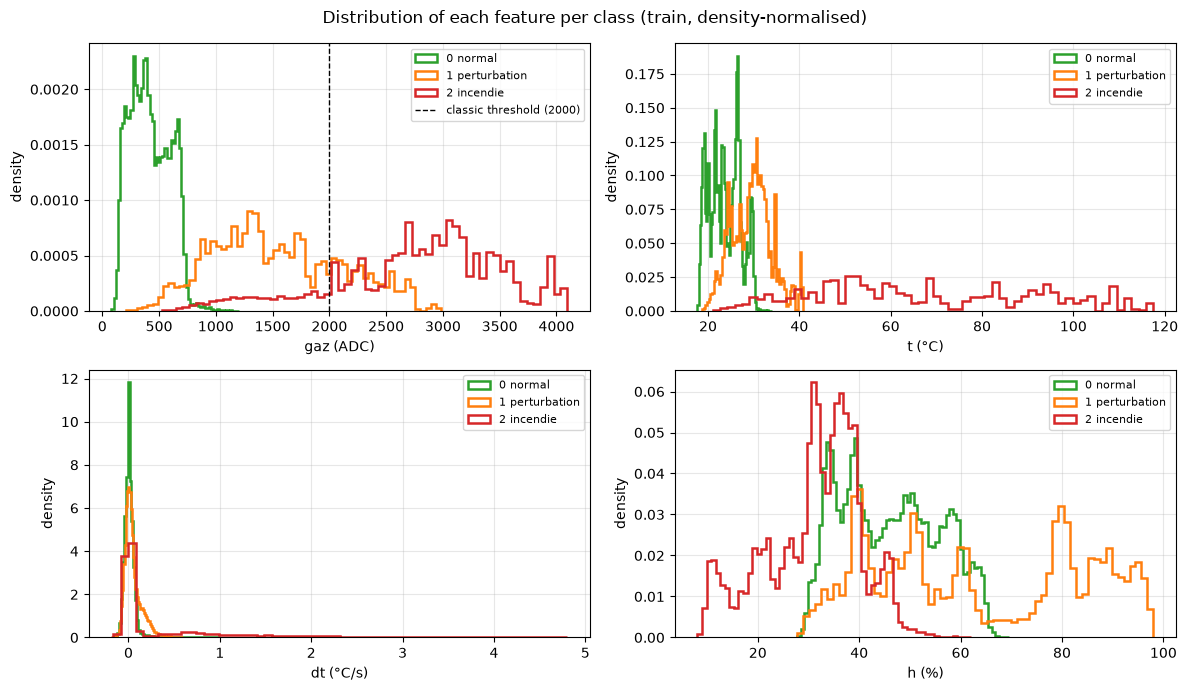

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (feat, unit) in zip(axes.ravel(), [("gaz", "ADC"), ("t", "°C"), ("dt", "°C/s"), ("h", "%")]):
    for c in (0, 1, 2):
        ax.hist(train.loc[train["y"] == c, feat], bins=60, density=True, histtype="step",
                linewidth=1.8, color=COLORS[c], label=CLASS_NAMES[c])
    if feat == "gaz":
        ax.axvline(SEUIL_CLASSIQUE, color="black", linestyle="--", linewidth=1, label="classic threshold (2000)")
    ax.set_xlabel(f"{feat} ({unit})")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)
fig.suptitle("Distribution of each feature per class (train, density-normalised)")
fig.tight_layout()
plt.show()


## 3. Quelques épisodes

Un épisode par type de scénario (le plus petit `episode_id` du train). La ligne rouge pointillée marque la première seconde dont le label est supérieur à 0 ; la ligne noire est le seuil `gaz = 2000`.


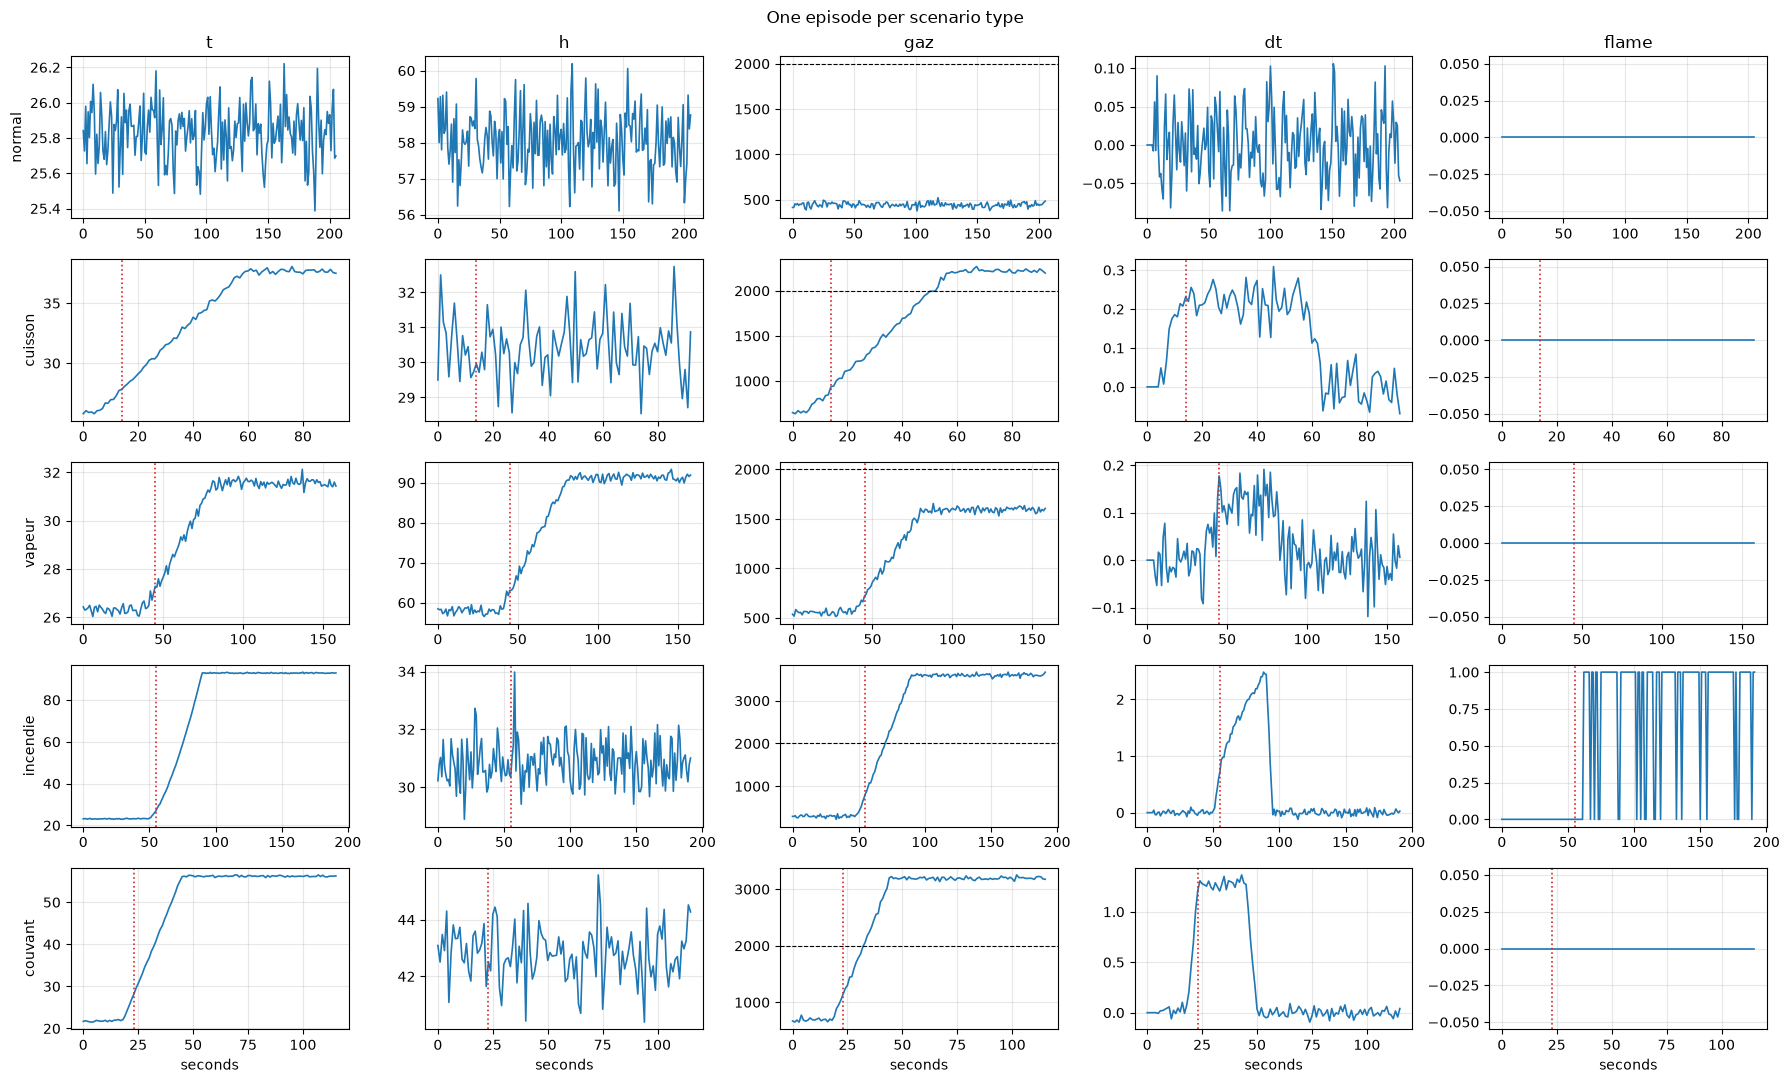

episodes shown [M]
    kind  episode_id  seconds  first_label_second  label
  normal           1      206                 NaN      0
 cuisson         150       93                14.0      1
  vapeur         251      159                45.0      1
incendie         350      192                55.0      2
 couvant         470      116                23.0      2


In [4]:
sample_ids = {k: int(train.loc[train["kind"] == k, "episode_id"].min()) for k in KINDS}
fig, axes = plt.subplots(len(KINDS), 5, figsize=(18, 11), sharex="row")
summary = []
for r, kind in enumerate(KINDS):
    ep = train[train["episode_id"] == sample_ids[kind]].reset_index(drop=True)  # index = seconds
    labelled = ep.index[ep["y"] > 0]
    onset = int(labelled[0]) if len(labelled) else None
    summary.append({"kind": kind, "episode_id": sample_ids[kind], "seconds": len(ep),
                    "first_label_second": onset, "label": int(ep["y"].max())})
    for ax, feat in zip(axes[r], ["t", "h", "gaz", "dt", "flame"]):
        ax.plot(ep.index, ep[feat], color="tab:blue", linewidth=1.2)
        if onset is not None:
            ax.axvline(onset, color="tab:red", linestyle=":", linewidth=1.2)
        if feat == "gaz":
            ax.axhline(SEUIL_CLASSIQUE, color="black", linestyle="--", linewidth=0.8)
        if r == 0:
            ax.set_title(feat)
    axes[r][0].set_ylabel(kind)
for ax in axes[-1]:
    ax.set_xlabel("seconds")
fig.suptitle("One episode per scenario type")
fig.tight_layout()
plt.show()
print("episodes shown [M]")
print(pd.DataFrame(summary).to_string(index=False))


## 4. Le détecteur classique face aux classes

Part des lignes où `gaz >= 2000` déclenche une alarme, selon la vraie classe. Sur la classe 1 c'est un taux de fausses alarmes ; sur la classe 2, le complément à 100 est la part de lignes d'incendie non détectées. Mesure par ligne, pas par épisode.


In [5]:
train["alarme_seuil"] = (train["gaz"] >= SEUIL_CLASSIQUE).astype(int)

by_class = train.groupby("y")["alarme_seuil"].mean().mul(100).round(1)
by_class.index = [CLASS_NAMES[c] for c in by_class.index]
print("share of rows where the classic detector fires, per true class (%) [M]")
print(by_class.to_string())
print()
by_kind = train.groupby("kind")["alarme_seuil"].mean().mul(100).round(1).reindex(KINDS)
print("same, per scenario type (%) [M]")
print(by_kind.to_string())


share of rows where the classic detector fires, per true class (%) [M]
0 normal           0.0
1 perturbation    24.4
2 incendie        85.3

same, per scenario type (%) [M]
kind
normal       0.0
cuisson     37.7
vapeur       0.0
incendie    68.3
couvant     64.5


## 5. `gaz` seul sépare-t-il les classes 1 et 2 ?

On ne garde que les lignes de classe 1 ou 2 du train.
1. AUC de chaque feature prise seule (0,5 = aucune séparation, 1,0 = séparation parfaite).
2. Arbre de décision de profondeur 4 (la profondeur du modèle de référence du brief, non réglée) sur `gaz` seul, sur `gaz` plus une autre feature, et sur les 5 features. Validation croisée par groupes d'épisodes (`GroupKFold`, 5 plis) : un épisode n'est jamais à la fois dans l'apprentissage et dans l'évaluation d'un pli.


In [6]:
sub = train[train["y"].isin([1, 2])]
is_fire = (sub["y"] == 2).to_numpy()

rows = []
for feat in FEATURES:
    auc = roc_auc_score(is_fire, sub[feat].to_numpy(dtype=float))
    rows.append({"feature": feat, "auc_1_vs_2": round(max(auc, 1 - auc), 3)})
auc_table = pd.DataFrame(rows).sort_values("auc_1_vs_2", ascending=False)
print(f"class 1 vs class 2 on {len(sub)} train rows")
print("single-feature AUC (0.5 = no separation, 1.0 = perfect) [M]")
print(auc_table.to_string(index=False))
print()

groups = sub["episode_id"].to_numpy()
subsets = {"gaz": ["gaz"], "gaz + t": ["gaz", "t"], "gaz + h": ["gaz", "h"],
           "gaz + dt": ["gaz", "dt"], "all 5 features": FEATURES}
cv_rows = []
for name, cols in subsets.items():
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=4, random_state=0),
        sub[cols].to_numpy(dtype=float), is_fire, groups=groups,
        cv=GroupKFold(n_splits=5), scoring="balanced_accuracy")
    cv_rows.append({"features": name, "balanced_acc_mean": round(float(scores.mean()), 3),
                    "std_over_folds": round(float(scores.std()), 3)})
cv_table = pd.DataFrame(cv_rows)
print("depth-4 tree, class 1 vs 2, grouped 5-fold CV on train, balanced accuracy [M]")
print(cv_table.to_string(index=False))
print()
gaz_only = cv_table.loc[cv_table["features"] == "gaz", "balanced_acc_mean"].item()
all_five = cv_table.loc[cv_table["features"] == "all 5 features", "balanced_acc_mean"].item()
print(f"balanced accuracy: gaz alone {gaz_only:.3f}, all 5 features {all_five:.3f}, gain {all_five - gaz_only:+.3f} [M]")


class 1 vs class 2 on 33207 train rows
single-feature AUC (0.5 = no separation, 1.0 = perfect) [M]
feature  auc_1_vs_2
      t       0.962
      h       0.938
    gaz       0.893
  flame       0.809
     dt       0.550



depth-4 tree, class 1 vs 2, grouped 5-fold CV on train, balanced accuracy [M]
      features  balanced_acc_mean  std_over_folds
           gaz              0.806           0.036
       gaz + t              0.917           0.021
       gaz + h              0.883           0.035
      gaz + dt              0.891           0.031
all 5 features              0.970           0.017

balanced accuracy: gaz alone 0.806, all 5 features 0.970, gain +0.164 [M]


## 6. Deux features à la fois

Nuage de points `gaz` contre `t`, puis `gaz` contre `h` (6 000 lignes du train tirées au hasard, graine 0). La ligne noire est le seuil classique.


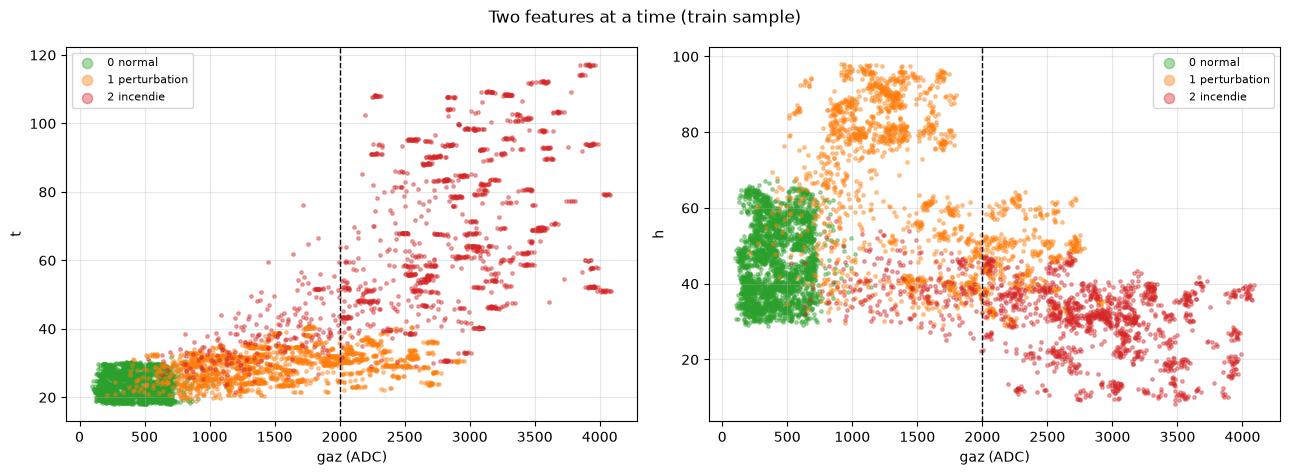

In [7]:
plot_df = train.sample(n=6000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, other in zip(axes, ["t", "h"]):
    for c in (0, 1, 2):
        d = plot_df[plot_df["y"] == c]
        ax.scatter(d["gaz"], d[other], s=6, alpha=0.4, color=COLORS[c], label=CLASS_NAMES[c])
    ax.axvline(SEUIL_CLASSIQUE, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("gaz (ADC)")
    ax.set_ylabel(other)
    ax.legend(markerscale=3, fontsize=8)
fig.suptitle("Two features at a time (train sample)")
fig.tight_layout()
plt.show()


## 7. Conclusions

Chiffres mesurés ci-dessus [M], sur le jeu synthétique v1, split train.

1. **Détecteur à seuil** (`gaz >= 2000`) : 0,0 % de déclenchements sur la classe 0 ; 24,4 % sur la classe 1, dus à la cuisson (37,7 %) et jamais à la vapeur (0,0 %) ; 85,3 % seulement sur la classe 2 (incendie 68,3 %, couvant 64,5 %). Il manque donc aussi des lignes d'incendie. Mesure par ligne, pas par épisode.
2. **`gaz` seul est insuffisant** pour séparer les classes 1 et 2 (AUC 0,893 ; exactitude équilibrée 0,806). Avec les 5 features : 0,970, soit +0,164 (écart-type 0,017 sur 5 plis par épisode). Ajouter une seule feature à `gaz` améliore déjà le résultat (`t` 0,917, `dt` 0,891, `h` 0,883). Cet écart justifie la fusion multi-capteurs (innovation A) **dans ce jeu synthétique**.
3. **`t` et `h` sont plus discriminants que `gaz` seul** (AUC 0,962 et 0,938). `dt` est faible (AUC 0,550) : après la montée, la température se stabilise et `dt` retombe vers 0.

Limites : jeu synthétique construit sur les conventions du contrat (section 4) ; la vapeur n'atteint jamais 2000 en `gaz`, donc le jeu ne montre les fausses alarmes du détecteur classique que sur la cuisson ; arbre de profondeur 4 non réglé, évalué sur le train seulement ; ces chiffres ne disent rien sur de vrais capteurs.
